# Kalman Filter

**Seong Cho** · ACME Volume 3

**Lab objective:** implement a Kalman filter and use it to track a simulated projectile from noisy observations, predict its future path, and rewind its estimated state back toward the launch point.

<sub>Lab specification from the *Volume 3* lab materials of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Solutions are my own.</sub>

The spec's problem statements weren't kept with my files, so each problem shows only my solution.

In [1]:
import numpy as np
from numpy import linalg as la
import matplotlib.pyplot as plt

## The `KalmanFilter` class

The model is $x_{k+1} = Fx_k + u + \varepsilon_k$ with $\varepsilon_k \sim N(0, Q)$, observed as $z_k = Hx_k + \delta_k$ with $\delta_k \sim N(0, R)$. `evolve()` simulates states and observations, `estimate()` runs the predict and update steps of the filter over a sequence of observations, `predict()` steps the model forward without observations, and `rewind()` steps it backward by solving $Fx_{k-1} = x_k - u$.

In [2]:
class KalmanFilter(object):
    def __init__(self,F,Q,H,R,u):
        """
        Initialize the dynamical system models.
        Parameters
        ----------
        F : ndarray of shape (n,n)
        The state transition model.
        Q : ndarray of shape (n,n)
        The covariance matrix for the state noise.
        H : ndarray of shape (m,n)
        The observation model.
        R : ndarray of shape (m,m)
        The covariance matric for observation noise.
        u : ndarray of shape (n,)
        The control vector.
        """
        self.F = F
        self.Q = Q
        self.H = H
        self.R = R
        self.u = u
        self.n = len(F)
        self.m = len(R)
    
    def evolve(self,x0,N):
        """
        Compute the first N states and observations generated by the Kalman
        system.
        Parameters
        ----------
        x0 : ndarray of shape (n,)
            The initial state.
        N : integer
            The number of time steps to evolve.
        Returns
        -------
        states : ndarray of shape (n,N)
            States 0 through N-1, given by each column.
        obs : ndarray of shape (m,N)
            Observations 0 through N-1, given by each column.
        """
        delta = np.random.multivariate_normal(np.zeros(self.m), self.R)
        z0 = self.H @ x0 + delta
        X = [x0]
        Z = [z0]
        for _ in range(N-1):
            eps = np.random.multivariate_normal(np.zeros(self.n), self.Q)
            xt = self.F @ x0 + self.u + eps
            delta = np.random.multivariate_normal(np.zeros(self.m), self.R)
            zt = self.H @ xt + delta
            X.append(xt)
            Z.append(zt)
            x0 = xt
            z0 = zt
        return np.stack(X).T, np.stack(Z).T
    
    def estimate(self,x,P,z):
        """
        Compute the state estimates using the Kalman filter.
        If x and P correspond to time step k, then z is a sequence of
        observations starting at time step k+1.
        Parameters
        ----------
        x : ndarray of shape (n,)
            The initial state estimate.
        P : ndarray of shape (n,n)
            The initial error covariance matrix.
        z : ndarray of shape(m,N)
            Sequence of N observations (each column is an observation).
        Returns
        -------
        out : ndarray of shape (n,N)
            Sequence of state estimates (each column is an estimate).
        """
        X = [x]
        for zt in z.T:
            x_predict = self.F @ x + self.u
            P_predict = self.F @ P @ self.F.T + self.Q
            y = zt - self.H @ x_predict
            S = self.H @ P_predict @ self.H.T + self.R
            K = P_predict @ self.H.T @ la.inv(S)
            x = x_predict + K @ y
            P = (np.eye(self.n) - K @ self.H) @ P_predict
            X.append(x)
        return np.stack(X).T
    
    def predict(self,x,k):
        """
        Predict the next k states in the absence of observations.
        Parameters
        ----------
        x : ndarray of shape (n,)
        The current state estimate.
        k : integer
        The number of states to predict.
        Returns
        -------
        out : ndarray of shape (n,k)
        The next k predicted states.
        """
        X = []
        for _ in range(k):
            x1 = self.F @ x + self.u
            x = x1
            X.append(x)
        return np.stack(X).T
    
    def rewind(self,x,k):
        """
        Predict the k states preceding the current state estimate x.
        Parameters
        ----------
        x : ndarray of shape (n,)
        The current state estimate.
        k : integer
        The number of preceding states to predict.
        Returns
        -------
        out : ndarray of shape (n,k)
        The k preceding predicted states.
        """
        X = []
        for _ in range(k):
            x1 = la.solve(self.F, x - self.u)
            x = x1
            X.append(x)
        return np.stack(X).T

## Problem 2: The projectile model

The state is $(s_x, s_y, v_x, v_y)$, position and velocity, with time step $0.1$; the control vector applies gravity to the vertical velocity, and only the position is observed.

In [3]:
Q = 0.1 * np.eye(4)
R = 5000 * np.eye(2)
F = np.array([[1, 0, 0.1, 0],
              [0, 1, 0, 0.1],
              [0, 0, 1, 0],
              [0, 0, 0, 1]])
H = np.array([[1, 0, 0, 0],
              [0, 1, 0, 0]])
u = np.array([0, 0, 0, -0.98])
kf = KalmanFilter(F, Q, H, R, u)

## Problem 3: Simulating the projectile

`evolve()` draws from NumPy's global random state, seeded here so the saved plots are reproducible.

In [4]:
np.random.seed(0)

In [5]:
x0 = np.array([0, 0, 300, 600])
X, Z = kf.evolve(x0, 1250)

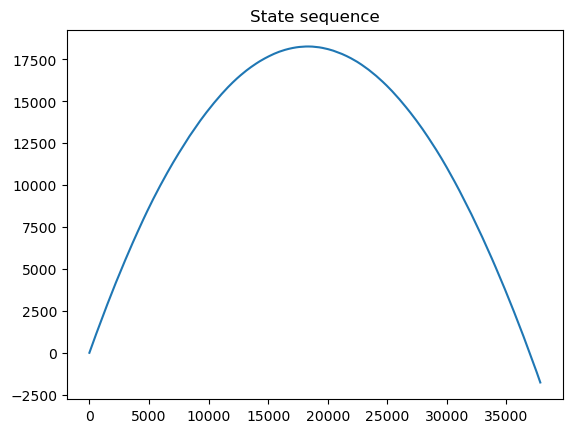

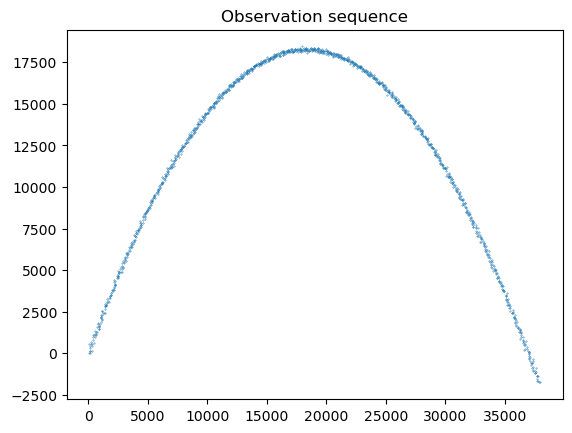

In [6]:
plt.plot(X[0], X[1])
plt.title("State sequence")
plt.show()

plt.scatter(Z[0], Z[1], s=0.1)
plt.title("Observation sequence")
plt.show()

Shapes, and the observation noise against $R = 5000I$ (standard deviation $\sqrt{5000} \approx 70.7$ per coordinate):

In [7]:
print(X.shape, Z.shape)
assert X.shape == (4, 1250) and Z.shape == (2, 1250)
assert np.allclose(X[:, 0], x0)
noise = Z - H @ X
print("observation noise std:", noise.std(axis=1).round(1))
assert np.allclose(noise.std(axis=1), np.sqrt(5000), rtol=0.1)

(4, 1250) (2, 1250)
observation noise std: [70.1 70.5]


## Problem 5: Filtering the observations

The filter starts at time step 200 from the observed position and a velocity estimated from the differences of the next observations (divided by the time step $0.1$), then runs on the observations from step 201 to 799.

In [8]:
s_x = Z[0, 200]
s_y = Z[1, 200]
V_x = np.diff(Z[0])[200:209].mean() * 10
V_y = np.diff(Z[1])[200:209].mean() * 10
x_200 = np.array([s_x, s_y, V_x, V_y])
P_200 = 1e6 * kf.Q
estimates = kf.estimate(x_200, P_200, Z[:, 201:800])

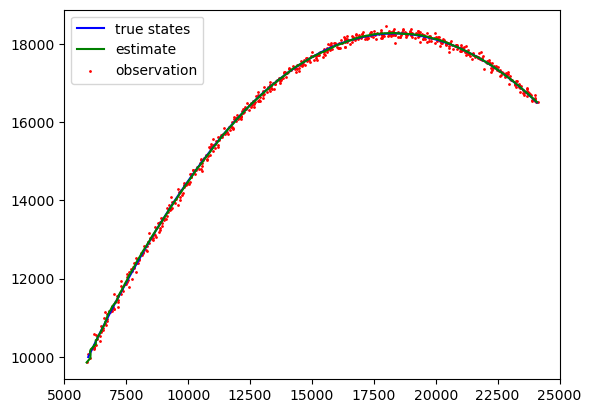

In [9]:
plt.plot(X[0, 200:800], X[1, 200:800], c='b', label="true states")
plt.plot(estimates[0], estimates[1], c='g', label="estimate")
plt.scatter(Z[0, 200:800], Z[1, 200:800], s=1, c='r', label="observation")
plt.legend()
plt.show()

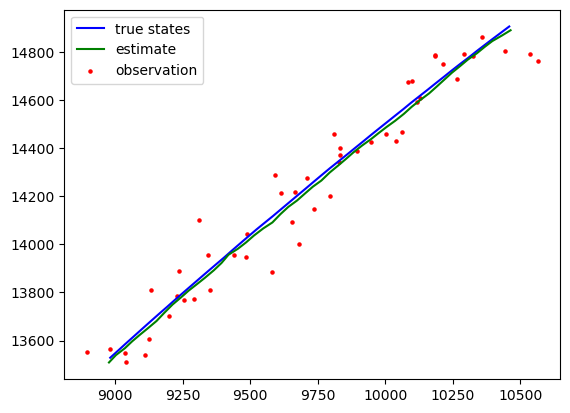

In [10]:
plt.plot(X[0, 300:350], X[1, 300:350], c='b', label="true states")
plt.plot(estimates[0, 100:150], estimates[1, 100:150], c='g', label="estimate")
plt.scatter(Z[0, 300:350], Z[1, 300:350], s=5, c='r', label="observation")
plt.legend()
plt.show()

`estimate()` returns the initial estimate as its first column, so column $j$ is the estimate of state $200 + j$. The filtered positions are much closer to the true positions than the raw observations are:

In [11]:
print(estimates.shape)
assert estimates.shape == (4, 600)
err_obs = la.norm(Z[:, 201:800] - X[:2, 201:800], axis=0)
err_est = la.norm(estimates[:2, 1:] - X[:2, 201:800], axis=0)
print(f"mean position error: {err_obs.mean():.1f} (observations), {err_est.mean():.1f} (filter)")
assert err_est.mean() < err_obs.mean() / 3

(4, 600)
mean position error: 87.8 (observations), 16.2 (filter)


## Problem 7: Predicting the rest of the path

From the last filtered estimate (step 799), `predict()` steps the model forward 450 times without observations, to step 1249.

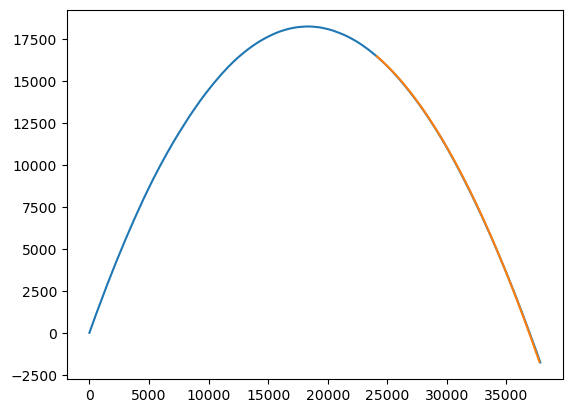

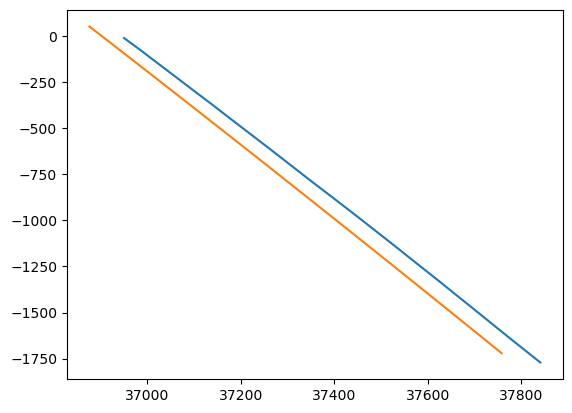

In [12]:
xhat_800 = estimates[:, -1]
x_future = kf.predict(xhat_800, 450)
plt.plot(X[0], X[1])
plt.plot(x_future[0], x_future[1])
plt.show()

plt.plot(X[0, -30:], X[1, -30:])
plt.plot(x_future[0, -30:], x_future[1, -30:])
plt.show()

Without noise, $k$ steps of the model give $F^k x + \sum_{j=0}^{k-1} F^j u$; `predict()` matches this closed form:

In [13]:
def closed_form(x, k):
    return np.linalg.matrix_power(F, k) @ x + sum(np.linalg.matrix_power(F, j) @ u for j in range(k))

for k in [1, 10, 450]:
    assert np.allclose(x_future[:, k-1], closed_form(xhat_800, k))
print("predicted final position:", x_future[:2, -1].round(1))
print("true final position:     ", X[:2, -1].round(1))

predicted final position: [37757.5 -1720.5]
true final position:      [37840.3 -1771.1]


## Problem 9: Rewinding to the launch point

`rewind()` steps the model backward from the filtered estimates at steps 250 and 600, to step 0.

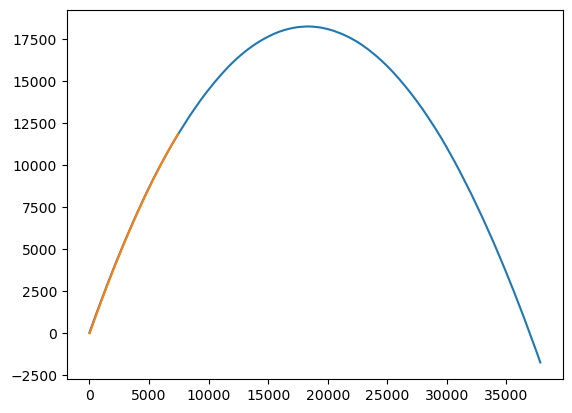

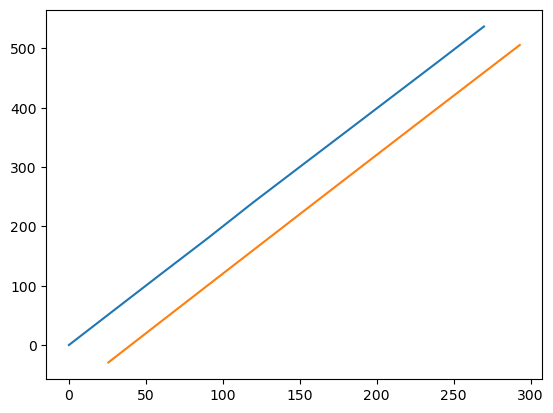

In [14]:
xhat_250 = estimates[:, 50]
x_prev = kf.rewind(xhat_250, 250)
plt.plot(X[0], X[1])
plt.plot(x_prev[0], x_prev[1])
plt.show()

plt.plot(X[0, :10], X[1, :10])
plt.plot(x_prev[0, -10:], x_prev[1, -10:])
plt.show()

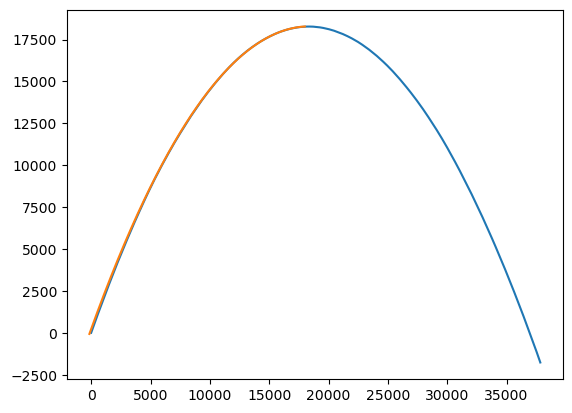

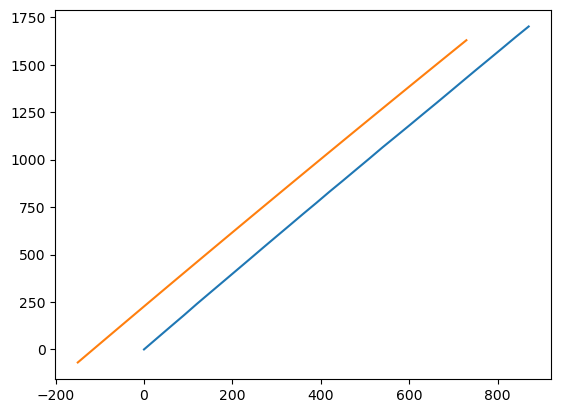

In [15]:
xhat_600 = estimates[:, 400]
x_prev = kf.rewind(xhat_600, 600)
plt.plot(X[0], X[1])
plt.plot(x_prev[0], x_prev[1])
plt.show()

plt.plot(X[0, :30], X[1, :30])
plt.plot(x_prev[0, -30:], x_prev[1, -30:])
plt.show()

Rewinding from 250 does significantly better. This is obvious since then there are less errors in the beginning estimate and less time steps it needs to predict.

`rewind()` undoes `predict()`, and the distances of the two rewound launch points from the true launch point $(0, 0)$ in this run:

In [16]:
x = estimates[:, 100]
assert np.allclose(kf.rewind(kf.predict(x, 25)[:, -1], 25)[:, -1], x)
for start, xhat in [(250, xhat_250), (600, xhat_600)]:
    launch = kf.rewind(xhat, start)[:2, -1]
    print(f"rewound from step {start}: {launch.round(1)}, distance {la.norm(launch - X[:2, 0]):.1f}")

rewound from step 250: [ 25.6 -29.4], distance 39.0
rewound from step 600: [-149.8  -68.8], distance 164.8
